# Sesión 2 — MUBD

Ejecuta las celdas en orden. Cada resultado aparece debajo de la celda, y puedes volver a ejecutar cualquier análisis después de cambiar los datos o los parámetros.

## Lectura de datos

Abrimos la tabla de teléfonos móviles y la mostramos para poder inspeccionarla. Los campos están separados por `;`; `NA` y las celdas vacías representan valores ausentes.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

DATA_PATH = Path.cwd().parent.parent / "datos"

datos = pd.read_csv(DATA_PATH / 'Mobiles.txt', sep=';', na_values=['NA', ''])
display(datos)  # Vista interactiva de los datos.

,Gender,Age,Faculty,Brand,Colour,Provider,PlanType,Bill,PrimaryUse,No.Phones
0,Female,17,Arts,LG,Silver,Telstra,Plan,70.0,SMS,1
1,Male,21,Arts,Motorola,Silver,Overseas,Prepaid,200.0,Calls,3
2,Female,20,Arts,Samsung,Silver,Optus,Prepaid,30.0,Both,1
3,Male,23,Arts,NaN,NaN,NaN,NaN,NaN,NaN,2
4,Female,38,Arts,Nokia,Blue,Optus,Plan,120.0,Calls,3
...,...,...,...,...,...,...,...,...,...,...
174,Male,19,Science,Sony,Grey,Optus,Prepaid,40.0,SMS,2
175,Male,19,Science,Sony,Silver,Optus,Plan,50.0,SMS,2
176,Female,20,Science,NaN,NaN,NaN,NaN,NaN,NaN,1
177,Male,23,Science,NaN,NaN,NaN,NaN,NaN,NaN,1


## Estimación de la media poblacional

Primero examinamos la distribución numérica y gráficamente. La prueba de una muestra estima la media con su intervalo de confianza (IC) y contrasta, primero, la hipótesis de media igual a 0 y, después, igual a 50.

In [5]:
# Descriptiva numérica de las datos["Bill"]
datos["Bill"].describe()

count    174.000000
mean      46.850575
std       41.577570
min        0.000000
25%       25.000000
50%       35.000000
75%       60.000000
max      300.000000
Name: Bill, dtype: float64

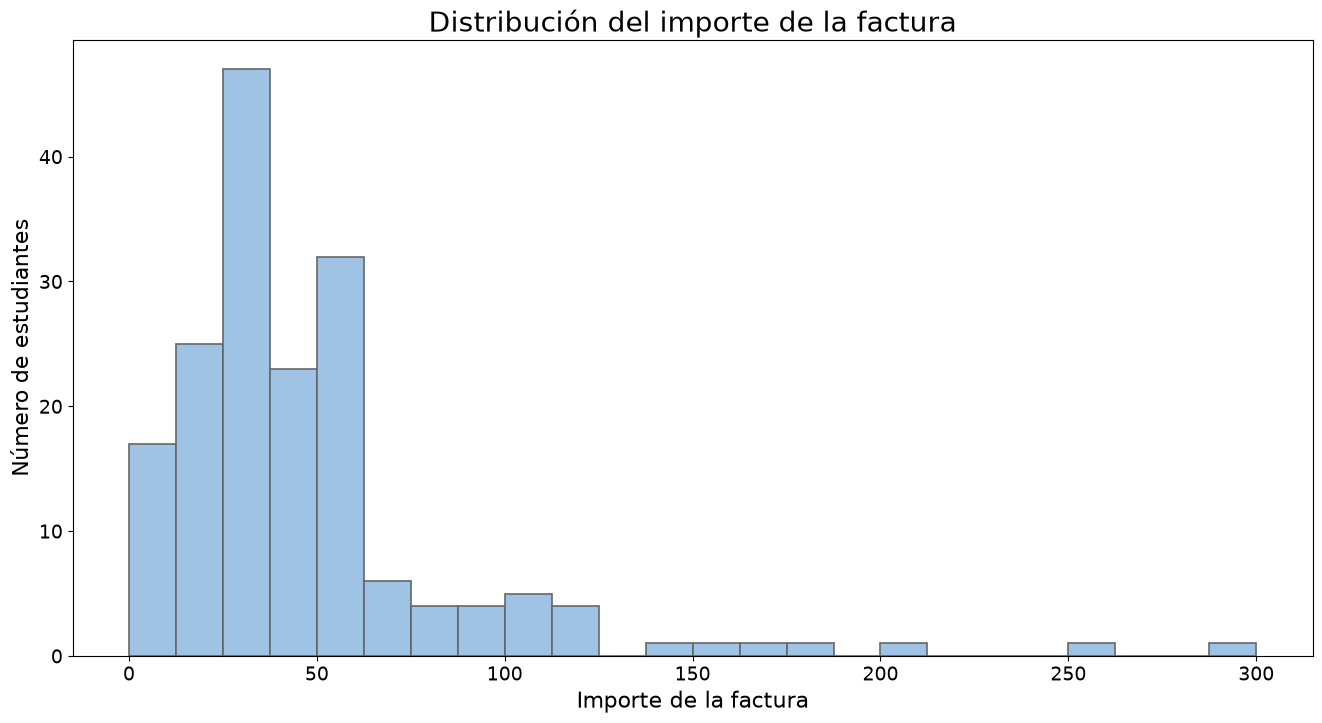

In [6]:
# Histograma de las facturas: azul claro de la diapositiva y bordes gris oscuro.
fig, ax = plt.subplots(figsize=(16, 8))
ax.hist(datos['Bill'], bins='auto', color='#9fc3e4', edgecolor='#666666', linewidth=1.2)
ax.set_title('Distribución del importe de la factura', fontsize=20)
ax.set_xlabel('Importe de la factura', fontsize=16)
ax.set_ylabel('Número de estudiantes', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

### Intervalo de confianza para la media

Queremos estimar el importe medio de la factura en la población a partir de una muestra. El **intervalo de confianza (IC) del 95 %** proporciona un rango de valores compatibles con los datos. Si repitiésemos el procedimiento con muchas muestras, aproximadamente el 95 % de los intervalos obtenidos contendrían la verdadera media poblacional; no significa que esta media tenga un 95 % de probabilidad de estar en este intervalo concreto.

La función descarta los valores ausentes, calcula la media y utiliza la **distribución t de Student** con $n-1$ grados de libertad y el error estándar de la media. Puedes cambiar `confianza` para obtener, por ejemplo, un IC del 99 %.

In [7]:
def intervalo_media(serie, confianza=0.95):
    """Intervalo de confianza bilateral para la media de una muestra."""
    muestra = pd.Series(serie).dropna()  # Excluimos los valores ausentes.
    ic = stats.t.interval(confianza, df=len(muestra)-1,
                          loc=muestra.mean(), scale=stats.sem(muestra))
    return pd.Series({'n': len(muestra), 'media': muestra.mean(),
                      'IC inferior': ic[0], 'IC superior': ic[1]})

In [8]:
# IC del 95 % para el importe medio de la factura.
display(intervalo_media(datos['Bill']))

n              174.000000
media           46.850575
IC inferior     40.629272
IC superior     53.071877
dtype: float64

### Contraste de hipótesis para una media: prueba t de una muestra

El intervalo **estima** la media; un contraste pregunta si los datos son compatibles con un valor propuesto $\mu_0$. Planteamos una **hipótesis nula** frente a una alternativa bilateral:

$$
\left\{
\begin{aligned}
H_0 &: \mu = \mu_0 \\
H_1 &: \mu \ne \mu_0
\end{aligned}
\right.
$$

La prueba t compara la diferencia entre la media observada y $\mu_0$ con el error estándar de la media.

El **estadístico t** mide esa diferencia en unidades de error estándar. El **valor p** indica cuán extremos serían los datos observados (o más) si $H_0$ fuera cierta. Por ejemplo, con un nivel de significación de 0,05, rechazamos $H_0$ si $p<0{,}05$; si no, **no la rechazamos**, lo que no demuestra que sea verdadera. La prueba presupone observaciones independientes y, para muestras pequeñas, una distribución aproximadamente normal.

In [9]:
def contraste_media(serie, mu=0):
    """Contraste bilateral de la hipótesis de que la media poblacional es mu."""
    muestra = pd.Series(serie).dropna()  # Usamos solo observaciones válidas.
    resultado = stats.ttest_1samp(muestra, popmean=mu)
    return pd.Series({'n': len(muestra), 'media': muestra.mean(),
                      'media hipotética': mu, 't': resultado.statistic,
                      'p-valor': resultado.pvalue})

#### Ejemplo 1: ¿podría ser cero la media poblacional?

Planteamos un contraste bilateral para la media de la factura:

$$
\left\{
\begin{aligned}
H_0 &: \mu = 0 \\
H_1 &: \mu \ne 0
\end{aligned}
\right.
$$

En `contraste_media`, el valor predeterminado de `mu` es 0. Fíjate en el valor p para decidir si los datos son compatibles con la hipótesis nula.

In [10]:
display(contraste_media(datos['Bill']))  # H₀: media poblacional = 0.

n                   1.740000e+02
media               4.685057e+01
media hipotética    0.000000e+00
t                   1.486382e+01
p-valor             9.837546e-33
dtype: float64

#### Ejemplo 2: ¿podría ser 50 la media poblacional?

Ahora contrastamos $H_0: \mu=50$ frente a $H_1: \mu\ne 50$. Solo cambia el valor propuesto mediante `mu=50`; la muestra y el procedimiento siguen siendo los mismos. Compara este valor p con el del ejemplo anterior.

In [11]:
display(contraste_media(datos['Bill'], mu=50))  # H₀: media poblacional = 50.

n                   174.000000
media                46.850575
media hipotética     50.000000
t                    -0.999187
p-valor               0.319100
dtype: float64

## Estimación de la desviación poblacional (opcional)

Usamos la fórmula del intervalo basada en cuantiles χ²: varianza, número de observaciones válidas e IC para la varianza y para la desviación típica. **Esta fórmula presupone normalidad.**

¿Se cumple la normalidad? Comparamos los cuantiles empíricos y teóricos: los datos no parecen normales si los puntos se separan de la recta.

### Alternativa: bootstrap

Generamos 10 000 muestras con reemplazo de la muestra original. Fijamos una semilla para repetir las simulaciones, representamos sus desviaciones típicas y tomamos los cuantiles 0,025 y 0,975 como IC del 95 %.

In [12]:
s2 = datos["Bill"].var(ddof=1)                            # Varianza muestral de las facturas.
n = datos["Bill"].notna().sum()                           # Tamaño muestral sin ausentes.

print(f"Varianza muestra: {s2} \nTamaño de muestra: {n}")

Varianza muestra: 1728.6943060261772 
Tamaño de muestra: 174


In [13]:
chi2 = stats.chi2.ppf(0.025, n-1)               # Cuantil inferior.
chi1 = stats.chi2.ppf(0.975, n-1)               # Cuantil superior.
LI = (n-1)*s2/chi1                              # Límite inferior del IC de la varianza.
LS = (n-1)*s2/chi2                              # Límite superior del IC de la varianza.
display(pd.Series({'Varianza inferior': LI, 'Varianza superior': LS,
                   'Desviación inferior': np.sqrt(LI), 'Desviación superior': np.sqrt(LS)}))

Varianza inferior      1415.264246
Varianza superior      2159.741507
Desviación inferior      37.619998
Desviación superior      46.473019
dtype: float64

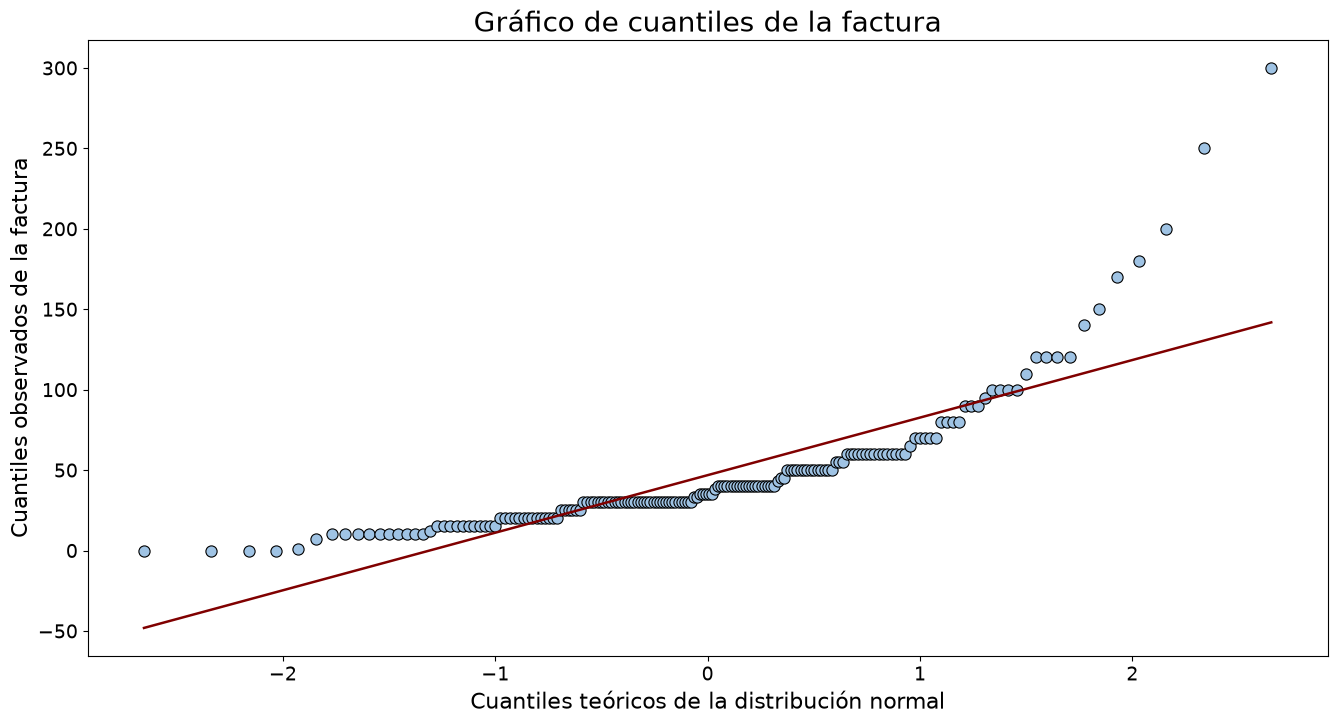

In [14]:
# Eliminamos los valores ausentes antes de comparar los cuantiles.
cuantiles, (pendiente, origen, _) = stats.probplot(datos['Bill'].dropna(), dist='norm')
teoricos, observados = cuantiles

# Mismo azul claro que el histograma anterior, con puntos más grandes y bordes negros.
fig, ax = plt.subplots(figsize=(16, 8))
ax.scatter(teoricos, observados, s=65, color='#9fc3e4',
           edgecolor='black', linewidth=0.8)
ax.plot(teoricos, pendiente * teoricos + origen, color='#800000', linewidth=1.8)
ax.set_title('Gráfico de cuantiles de la factura', fontsize=20)
ax.set_xlabel('Cuantiles teóricos de la distribución normal', fontsize=16)
ax.set_ylabel('Cuantiles observados de la factura', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

### Prueba de normalidad de Shapiro–Wilk

El gráfico de cuantiles permite valorar visualmente la normalidad. La **prueba de Shapiro–Wilk** la contrasta formalmente: compara la distribución de los datos con la que esperaríamos si procedieran de una población normal.

$$
\left\{
\begin{aligned}
H_0 &: \text{la distribución de las facturas es normal} \\
H_1 &: \text{la distribución de las facturas no es normal}
\end{aligned}
\right.
$$

El estadístico $W$ suele acercarse a 1 cuando los datos se ajustan a una distribución normal. Con un nivel de significación del 5 %, si el **valor p** es menor que $0{,}05$, rechazamos $H_0$; en caso contrario, no tenemos suficiente evidencia para rechazarla (**no** se demuestra que los datos sean normales). La prueba supone observaciones independientes y, como en el Q–Q plot, excluimos las facturas ausentes.

In [15]:
# Contraste de normalidad de Shapiro–Wilk para las facturas sin valores ausentes.
w, p_valor = stats.shapiro(datos['Bill'].dropna())
print(f'Shapiro–Wilk: W = {w:.4f}, valor p = {p_valor:.4g}')
if p_valor < 0.05:
    print('Se rechaza la normalidad al nivel del 5 %.')
else:
    print('No se rechaza la normalidad al nivel del 5 %.')

Shapiro–Wilk: W = 0.7336, valor p = 2.024e-16
Se rechaza la normalidad al nivel del 5 %.


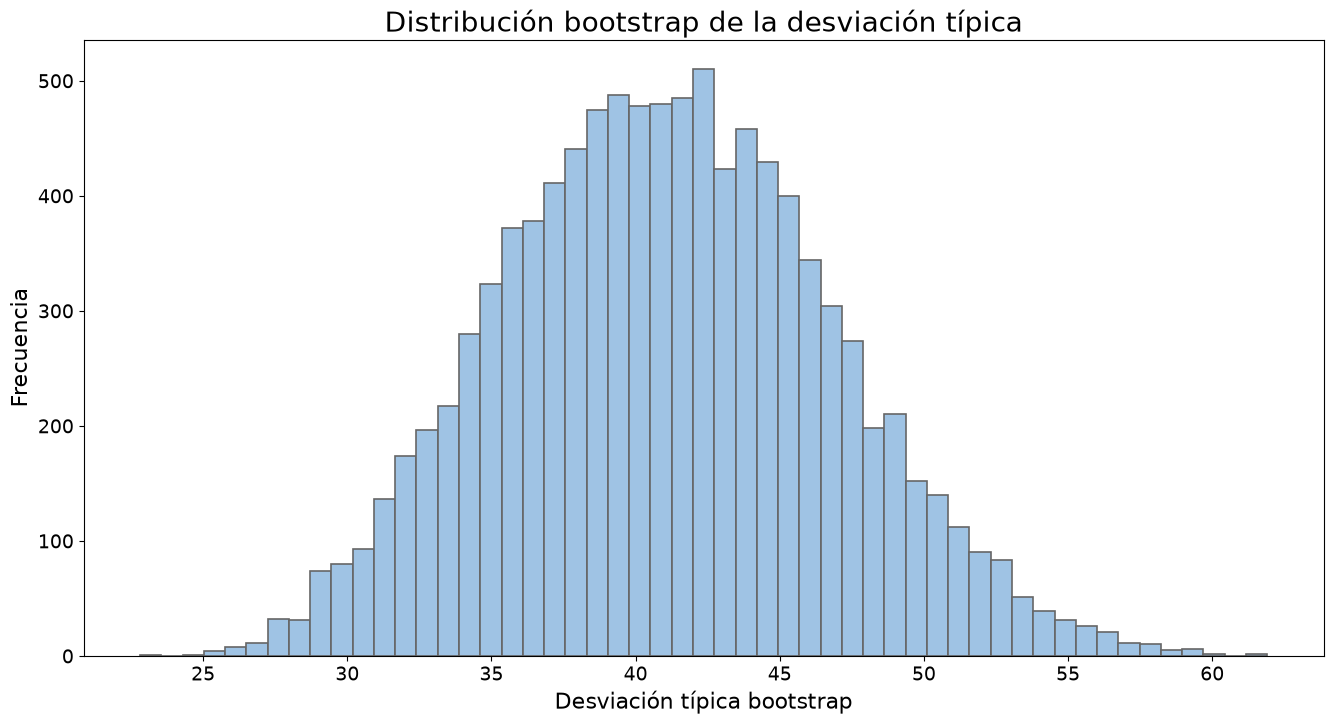

In [16]:
rng = np.random.default_rng(12345)             # Semilla para simulaciones reproducibles.
bill_validos = datos['Bill'].dropna().to_numpy()  # Excluimos las facturas ausentes.
m = np.array([np.std(rng.choice(bill_validos, size=len(bill_validos), replace=True), ddof=1)
              for _ in range(10_000)])          # 10 000 desviaciones bootstrap.
fig, ax = plt.subplots(figsize=(16, 8))
ax.hist(m, bins='auto', color='#9fc3e4', edgecolor='#666666', linewidth=1.2)
ax.set_title('Distribución bootstrap de la desviación típica', fontsize=20)
ax.set_xlabel('Desviación típica bootstrap', fontsize=16)
ax.set_ylabel('Frecuencia', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

### Intervalo de confianza bootstrap para la desviación típica

El histograma anterior muestra **10 000 desviaciones típicas muestrales**: cada una se calcula a partir de una muestra del mismo tamaño que los datos válidos, elegida **con reemplazo**. Así aproximamos cómo varía la estimación al repetir el muestreo.

Para obtener el **IC bootstrap del 95 % por el método de los percentiles**, tomamos los percentiles **2,5 % y 97,5 %** de esas 10 000 desviaciones: los valores centrales quedan entre ambos límites. El intervalo estima la **desviación típica poblacional**, no el rango que contiene el 95 % de las facturas individuales. A diferencia del IC basado en χ² de más arriba, este procedimiento no necesita suponer normalidad; sí requiere que la muestra sea representativa y sus observaciones sean independientes.

In [17]:
limite_inferior, limite_superior = np.quantile(m, [0.025, 0.975])
print(f'Percentil 2,5 % (límite inferior): {limite_inferior:.2f}')
print(f'Percentil 97,5 % (límite superior): {limite_superior:.2f}')
print(f'IC bootstrap del 95 % para la desviación típica poblacional: '
      f'[{limite_inferior:.2f}, {limite_superior:.2f}]')

Percentil 2,5 % (límite inferior): 30.26
Percentil 97,5 % (límite superior): 52.60
IC bootstrap del 95 % para la desviación típica poblacional: [30.26, 52.60]


## Estimación de una proporción

Queremos estimar qué proporción de estudiantes tiene tarjeta prepago. Primero calculamos la **proporción observada**: dividimos el número de estudiantes con contrato `Prepaid` entre quienes tienen informado el tipo de contrato, **no** entre todas las filas. Después calculamos dos intervalos de confianza del 95 % y, por separado, contrastamos si la proporción poblacional podría ser 0,5.

In [18]:
e = (datos['PlanType'] == 'Prepaid').sum()      # Estudiantes con tarjeta prepago.
n_plan = datos['PlanType'].notna().sum()       # Estudiantes con tipo de contrato conocido.
print(f'Prepago: {e} de {n_plan}; proporción observada = {e/n_plan:.4f}')

Prepago: 98 de 174; proporción observada = 0.5632


### Intervalo de confianza aproximado del 95 %: método de Wilson

La proporción observada estima la proporción real de estudiantes con tarjeta prepago. El **intervalo de Wilson** da un rango de valores poblacionales compatibles con la muestra usando una aproximación basada en la distribución binomial; se comporta mejor que el intervalo aproximado más sencillo cuando la proporción está cerca de 0 o de 1. Con un nivel de confianza del 95 %, calculamos sus límites inferior y superior. El intervalo estima la proporción **poblacional**, no la proporción de una persona concreta.

In [19]:
from statsmodels.stats.proportion import proportion_confint

ic_wilson = proportion_confint(e, n_plan, alpha=0.05, method='wilson')
print(f'IC Wilson del 95 % para la proporción de prepago: [{ic_wilson[0]:.4f}, {ic_wilson[1]:.4f}]')

IC Wilson del 95 % para la proporción de prepago: [0.4889, 0.6348]


### Intervalo de confianza binomial exacto del 95 %

El intervalo **exacto de Clopper–Pearson** utiliza la distribución binomial, sin recurrir a una aproximación normal. En muestras pequeñas es especialmente útil; suele ser más conservador (y a menudo más amplio) que el de Wilson. Seguimos estimando la misma proporción poblacional de estudiantes con tarjeta prepago, con los mismos `e` casos y `n_plan` observaciones válidas.

In [20]:
ic_exacto = stats.binomtest(e, n_plan).proportion_ci(confidence_level=0.95, method='exact')
print(f'IC binomial exacto del 95 % para la proporción de prepago: '
      f'[{ic_exacto.low:.4f}, {ic_exacto.high:.4f}]')

IC binomial exacto del 95 % para la proporción de prepago: [0.4861, 0.6381]


### Contraste binomial: ¿es 0,5 la proporción de prepago?

Los intervalos **estiman** la proporción; este contraste bilateral pregunta si los datos son compatibles con que **la mitad** de los estudiantes con contrato conocido tenga tarjeta prepago:

$$
\left\{
\begin{aligned}
H_0 &: \pi = 0{,}5 \\
H_1 &: \pi \ne 0{,}5
\end{aligned}
\right.
$$

Aquí $\pi$ es la proporción **poblacional** de prepago. La prueba binomial exacta calcula el **valor p** sin aproximación normal. Si es menor que $0{,}05$, rechazamos $H_0$; de lo contrario, **no la rechazamos** (no significa que $\pi$ sea exactamente 0,5). Se supone que las observaciones son independientes y que cada estudiante tiene la misma probabilidad de ser prepago.

In [21]:
resultado_binomial = stats.binomtest(e, n_plan, p=0.5, alternative='two-sided')
print(f'Valor p del contraste binomial bilateral (H₀: π = 0,5): {resultado_binomial.pvalue:.4g}')
if resultado_binomial.pvalue < 0.05:
    print('Se rechaza H₀ al nivel del 5 %.')
else:
    print('No se rechaza H₀ al nivel del 5 %.')

Valor p del contraste binomial bilateral (H₀: π = 0,5): 0.1111
No se rechaza H₀ al nivel del 5 %.


### Ejercicio 2.1

1. Lee el fichero de vuelos y guarda los datos en `datos2`.
2. Estima el IC del **95 %** para la media del retraso en las llegadas (`arr_delay`) mediante una prueba t de una muestra.
3. Comprueba gráficamente que la variable no sigue una distribución normal y estima mediante bootstrap el IC del **90 %**, no del 95 %, para la desviación típica del retraso en las llegadas.
4. Estima el IC del **99 %**, no del 95 %, para la proporción de vuelos que llegan con retraso.

In [22]:
# 2.1.1 — Lectura de los datos de vuelos.
# Estos datos se utilizarán también en los ejercicios 2.2, 2.3 y 2.4.
datos2 = pd.read_csv(DATA_PATH / 'flights.txt', sep='\t', na_values=['@', 'NA', ''])
display(datos2.head())
# Comprueba las columnas, los tipos de datos y qué valores se han leído como ausentes.

,year,month,day,dep_time,dep_delay,arr_time,arr_delay,carrier,tailnum,flight,origin,dest,air_time,distance,hour,minute
0,2013,1,1,517.0,2.0,830.0,11.0,UA,N14228,1545,EWR,IAH,227.0,1400,5.0,17.0
1,2013,1,1,533.0,4.0,850.0,20.0,UA,N24211,1714,LGA,IAH,227.0,1416,5.0,33.0
2,2013,1,1,542.0,2.0,923.0,33.0,AA,N619AA,1141,JFK,MIA,160.0,1089,5.0,42.0
3,2013,1,1,544.0,-1.0,1004.0,-18.0,B6,N804JB,725,JFK,BQN,183.0,1576,5.0,44.0
4,2013,1,1,554.0,-6.0,812.0,-25.0,DL,N668DN,461,LGA,ATL,116.0,762,5.0,54.0


In [23]:
# 2.1.2 — IC del 95 % para el retraso medio en la llegada.
# Selecciona arr_delay y descarta los retrasos ausentes antes de contar vuelos o calcular la media.
# Reutiliza la función intervalo_media o el procedimiento t de una muestra explicado arriba.
# ¿Qué nivel de confianza debes indicar y cómo interpretarías los límites obtenidos?
# El intervalo estima la media poblacional, no el retraso de un vuelo concreto.

In [24]:
# 2.1.3 — Normalidad gráfica e IC bootstrap del 90 % para la desviación típica.
# Usa los retrasos de llegada válidos; un histograma y un gráfico Q–Q ayudan a valorar la normalidad.
# ¿Se apartan los cuantiles observados de la recta, especialmente en las colas?
# Reutiliza la idea de bootstrap anterior: remuestrea con reemplazo y calcula una desviación típica por muestra.
# Para un IC del 90 % por percentiles, ¿qué dos cuantiles dejan el 90 % central de las estimaciones?
# Recuerda que ahora la variable es arr_delay, no Bill, y que el resultado estima su desviación poblacional.

In [25]:
# 2.1.4 — IC del 99 % para la proporción de vuelos que llegan con retraso.
# Decide qué significa 'con retraso' (arr_delay > 0): cero o negativo cuenta como sin retraso.
# Usa solo vuelos con arr_delay conocido tanto para el número de llegadas tardías como para el total.
# Adapta uno de los IC binomiales vistos antes (Wilson o exacto) al nivel de confianza pedido.
# ¿Qué valor de alpha corresponde al 99 %? Interpreta el IC para la proporción poblacional.

## Comparación de dos medias

### Muestras independientes

Comparamos el importe medio de la factura entre quienes tienen contrato `Plan` y `Prepaid`. Preparamos los dos grupos eliminando las facturas ausentes; después visualizamos sus distribuciones con un diagrama de cajas y un gráfico de puntos. Finalmente, estimamos la diferencia de medias y realizamos contrastes bilateral y unilateral por separado. **El orden importa:** en todos los cálculos la diferencia es la media de `Plan` menos la de `Prepaid`.

Recurso para explorar distribuciones muestrales: http://onlinestatbook.com/stat_sim/sampling_dist/

In [26]:
grupos = [(str(nombre), parte['Bill'].dropna()) for nombre, parte in datos.groupby('PlanType', sort=True)]
(nombre1, grupo1), (nombre2, grupo2) = grupos
print('Orden de la diferencia de medias:', nombre1, '-', nombre2)
print(f'Tamaños de los grupos: {nombre1} = {len(grupo1)}, {nombre2} = {len(grupo2)}')

Orden de la diferencia de medias: Plan - Prepaid
Tamaños de los grupos: Plan = 76, Prepaid = 98


#### Diagrama de cajas por tipo de contrato

El **boxplot** resume la mediana (línea central), el rango intercuartílico (caja), la extensión habitual de los datos (bigotes) y los valores atípicos (puntos). Permite comparar la posición y la dispersión de las facturas en ambos grupos, pero no muestra todas las observaciones.

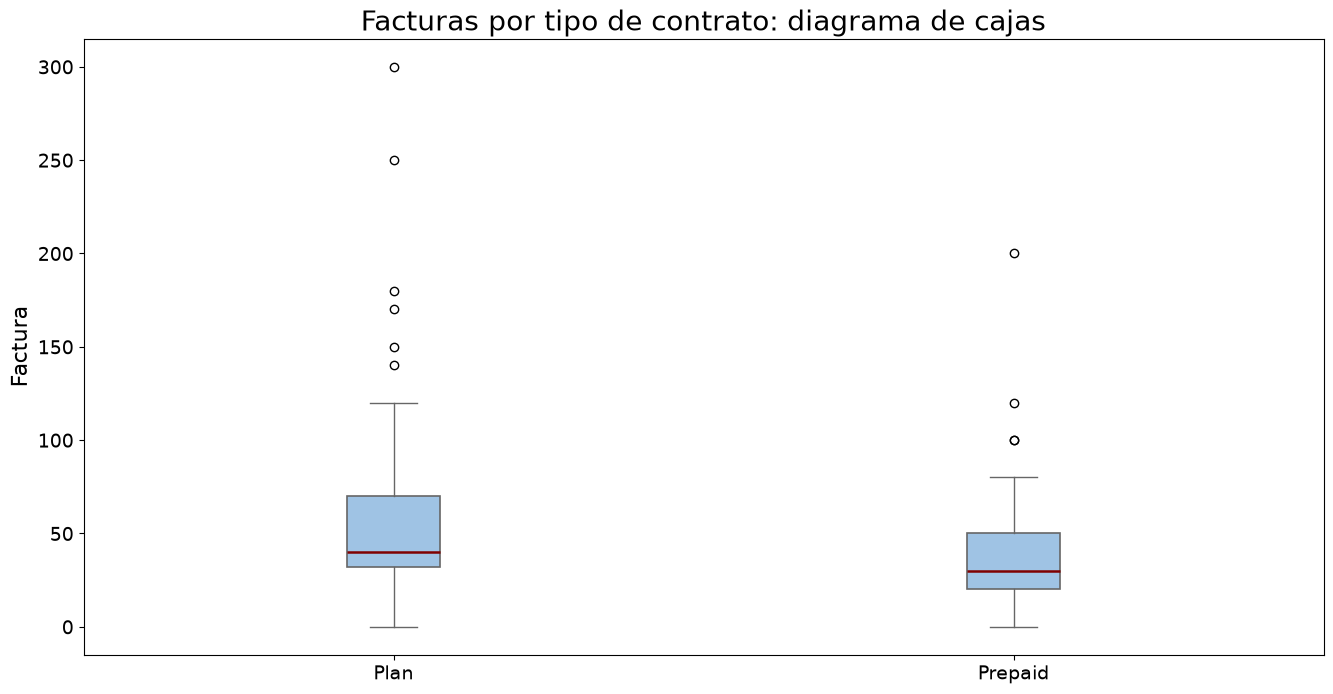

In [27]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.boxplot([grupo1, grupo2], tick_labels=[nombre1, nombre2], patch_artist=True,
           boxprops={'facecolor': '#9fc3e4', 'edgecolor': '#666666', 'linewidth': 1.2},
           whiskerprops={'color': '#666666'}, capprops={'color': '#666666'},
           medianprops={'color': '#800000', 'linewidth': 1.8})
ax.set_title('Facturas por tipo de contrato: diagrama de cajas', fontsize=20)
ax.set_ylabel('Factura', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

#### Gráfico de puntos (stripchart)

El **stripchart** representa cada factura individual. El pequeño desplazamiento horizontal aleatorio evita que los puntos con importes iguales queden totalmente superpuestos; **no cambia** el valor de la factura ni el grupo de cada estudiante.

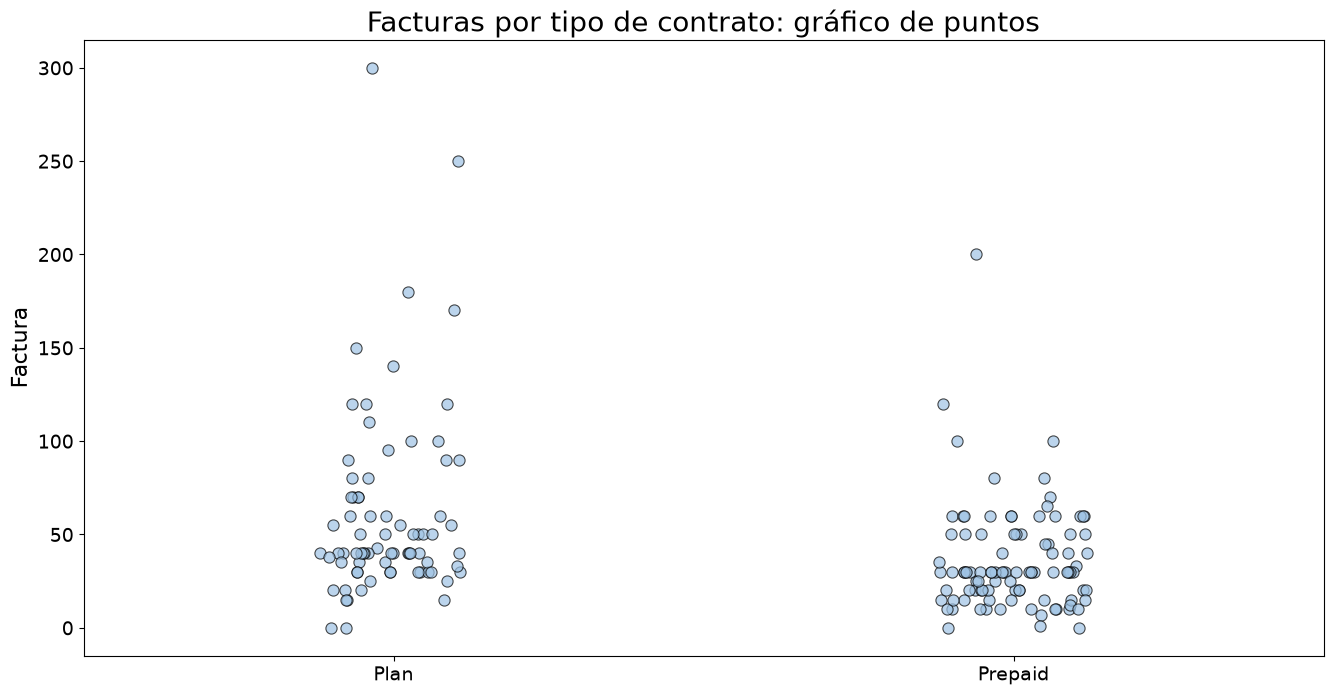

In [28]:
rng_puntos = np.random.default_rng(12345)  # Desplazamiento reproducible de los puntos.
fig, ax = plt.subplots(figsize=(16, 8))
for posicion, grupo in enumerate((grupo1, grupo2), start=1):
    x = posicion + rng_puntos.uniform(-0.12, 0.12, size=len(grupo))
    ax.scatter(x, grupo, s=65, color='#9fc3e4', edgecolor='black',
               linewidth=0.8, alpha=0.7)
ax.set_xlim(0.5, 2.5)
ax.set_xticks([1, 2], [nombre1, nombre2])
ax.set_title('Facturas por tipo de contrato: gráfico de puntos', fontsize=20)
ax.set_ylabel('Factura', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

#### IC del 95 % para la diferencia de medias

Estimamos $\mu_{\mathrm{Plan}}-\mu_{\mathrm{Prepaid}}$ con un **intervalo de confianza del 95 %**. Un intervalo completamente positivo indica que las facturas medias del primer grupo son mayores. Usamos la distribución t y una **varianza común** para ambos grupos (`usevar='pooled'`); este método presupone observaciones independientes y varianzas poblacionales iguales. Como la distribución de las facturas es asimétrica, conviene interpretar este modelo con cautela.

In [29]:
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW

comparacion = CompareMeans(DescrStatsW(grupo1), DescrStatsW(grupo2))
ic_95 = comparacion.tconfint_diff(alpha=0.05, usevar='pooled')
print(f'IC 95 % para la media de {nombre1} − la de {nombre2}: ({ic_95[0]:.2f}, {ic_95[1]:.2f})')

IC 95 % para la media de Plan − la de Prepaid: (13.44, 37.41)


#### IC del 99 % para la diferencia de medias

Repetimos la estimación con **mayor confianza (99 %)** sobre los mismos grupos y bajo el mismo supuesto de varianzas iguales. Al aumentar la confianza, el intervalo suele ser **más ancho**; compara sus límites con los del IC del 95 %.

In [30]:
ic_99 = comparacion.tconfint_diff(alpha=0.01, usevar='pooled')
print(f'IC 99 % para la media de {nombre1} − la de {nombre2}: ({ic_99[0]:.2f}, {ic_99[1]:.2f})')

IC 99 % para la media de Plan − la de Prepaid: (9.61, 41.24)


#### Contraste t bilateral: ¿son distintas las medias?

La **prueba t de dos muestras independientes** contrasta si las medias poblacionales de las facturas difieren, sin indicar de antemano cuál sería mayor:

$$
\left\{
\begin{aligned}
H_0 &: \mu_{\mathrm{Plan}} = \mu_{\mathrm{Prepaid}} \\
H_1 &: \mu_{\mathrm{Plan}} \ne \mu_{\mathrm{Prepaid}}
\end{aligned}
\right.
$$

El estadístico t compara la diferencia observada con su error estándar. El **valor p bilateral** mide cuán extrema sería una diferencia de esa magnitud (en cualquiera de las dos direcciones) si $H_0$ fuese cierta. Si $p<0{,}05$, rechazamos la igualdad de medias; si no, no la rechazamos. Esta versión (`equal_var=True`) presupone **independencia y varianzas poblacionales iguales**, además de normalidad aproximada para muestras pequeñas. La asimetría y los valores atípicos vistos antes aconsejan cautela; más adelante se comparan las varianzas.

In [31]:
resultado_bilateral = stats.ttest_ind(grupo1, grupo2, equal_var=True, alternative='two-sided')
print(f'Prueba t bilateral ({nombre1} frente a {nombre2}):')
print(f't = {resultado_bilateral.statistic:.4f}; p-valor = {resultado_bilateral.pvalue:.4g}')
if resultado_bilateral.pvalue < 0.05:
    print('Se rechaza la igualdad de medias al nivel del 5 %.')
else:
    print('No se rechaza la igualdad de medias al nivel del 5 %.')

Prueba t bilateral (Plan frente a Prepaid):
t = 4.1879; p-valor = 4.489e-05
Se rechaza la igualdad de medias al nivel del 5 %.


#### Contraste t unilateral: ¿es mayor la media de Plan?

Ahora examinamos una **dirección concreta**. Este contraste debe plantearse **antes de observar los resultados**: la alternativa dice que la factura media de `Plan` supera a la de `Prepaid`.

$$
\left\{
\begin{aligned}
H_0 &: \mu_{\mathrm{Plan}} \le \mu_{\mathrm{Prepaid}} \\
H_1 &: \mu_{\mathrm{Plan}} > \mu_{\mathrm{Prepaid}}
\end{aligned}
\right.
$$

Con los grupos en el orden `Plan`, `Prepaid`, `alternative='greater'` contrasta exactamente esa dirección. Si el **valor p unilateral** es menor que $0{,}05$, rechazamos $H_0$ en favor de que la media de `Plan` es mayor; si no, no tenemos evidencia suficiente para esa afirmación. Mantenemos los **mismos supuestos de independencia y varianzas iguales** que en la prueba bilateral.

In [32]:
resultado_unilateral = stats.ttest_ind(grupo1, grupo2, equal_var=True, alternative='greater')
print(f'Prueba t unilateral (media de {nombre1} mayor que la de {nombre2}):')
print(f't = {resultado_unilateral.statistic:.4f}; p-valor = {resultado_unilateral.pvalue:.4g}')
if resultado_unilateral.pvalue < 0.05:
    print(f'Se rechaza H₀: hay evidencia de que la media de {nombre1} es mayor.')
else:
    print(f'No hay evidencia suficiente de que la media de {nombre1} sea mayor.')

Prueba t unilateral (media de Plan mayor que la de Prepaid):
t = 4.1879; p-valor = 2.245e-05
Se rechaza H₀: hay evidencia de que la media de Plan es mayor.


### Datos apareados

En la encuesta de estudiantes, cada fila corresponde a la misma persona en **ambas** mediciones:

- `Sex`: sexo de la persona.
- `HrsSleep`: horas de sueño cada noche.
- `SQpick`: letra elegida entre Q y S.
- `Height`: altura en pulgadas.
- `RandNumb`: número entero entre 1 y 10 elegido al azar.
- `Fastest`: máxima velocidad a la que ha conducido, en millas por hora.
- `RtSpan`: longitud de la palma derecha, en centímetros.
- `LftSpan`: longitud de la palma izquierda, en centímetros.
- `Form`: orden en que se presentaron las opciones Q y S.

#### Lectura de datos y selección de pares completos

`pd.read_csv(..., sep='\t')` lee el fichero separado por tabulaciones; `display` muestra las filas para inspeccionarlas. Seleccionamos las columnas `LftSpan` y `RtSpan` y aplicamos `dropna()` **a ambas a la vez**: si a una persona le falta una medida, excluimos sus dos valores para no romper el emparejamiento. Mostramos cuántos pares completos quedan. Después veremos cada gráfico y cada prueba en una celda distinta.

Descripción de la encuesta: http://sites.stat.psu.edu/~dhunter/250h/data/readme.html

In [33]:
PennState1 = pd.read_csv(DATA_PATH / 'PennState1.txt', sep='\t')
display(PennState1)

# Conservamos únicamente a quienes tienen medidas de ambas palmas.
pares = PennState1[['LftSpan', 'RtSpan']].dropna()
print(f'Personas con ambas medidas: {len(pares)}; pares incompletos excluidos: {len(PennState1) - len(pares)}')

,Sex,HrsSleep,SQpick,Height,RandNumb,Fastest,RtSpan,LftSpan,Form
0,Male,5.0,S,67.0,3,110.0,21.5,21.5,SorQ
1,Male,7.0,S,75.0,9,109.0,22.5,22.5,SorQ
2,Male,6.0,S,73.0,7,90.0,23.5,24.0,SorQ
3,Female,7.5,S,64.0,8,80.0,20.0,21.0,SorQ
4,Female,7.0,S,63.0,7,75.0,19.0,19.0,SorQ
...,...,...,...,...,...,...,...,...,...
185,Male,6.0,Q,70.0,7,110.0,23.0,23.0,QorS
186,Male,6.0,Q,75.0,5,115.0,23.0,23.5,QorS
187,Male,3.0,Q,70.0,3,125.0,21.5,21.5,QorS
188,Male,8.0,Q,72.0,7,55.0,19.0,19.0,QorS


Personas con ambas medidas: 190; pares incompletos excluidos: 0


#### Diagrama de cajas de las longitudes

Comparamos las **distribuciones** de las palmas izquierda y derecha: la línea de cada caja es la mediana, la caja abarca el 50 % central de los valores, los bigotes muestran la extensión habitual y los puntos aislados señalan posibles valores atípicos. Sirve para ver posición y dispersión de cada lado, pero **no permite saber qué dos medidas corresponden a la misma persona**; para eso usamos el gráfico siguiente.

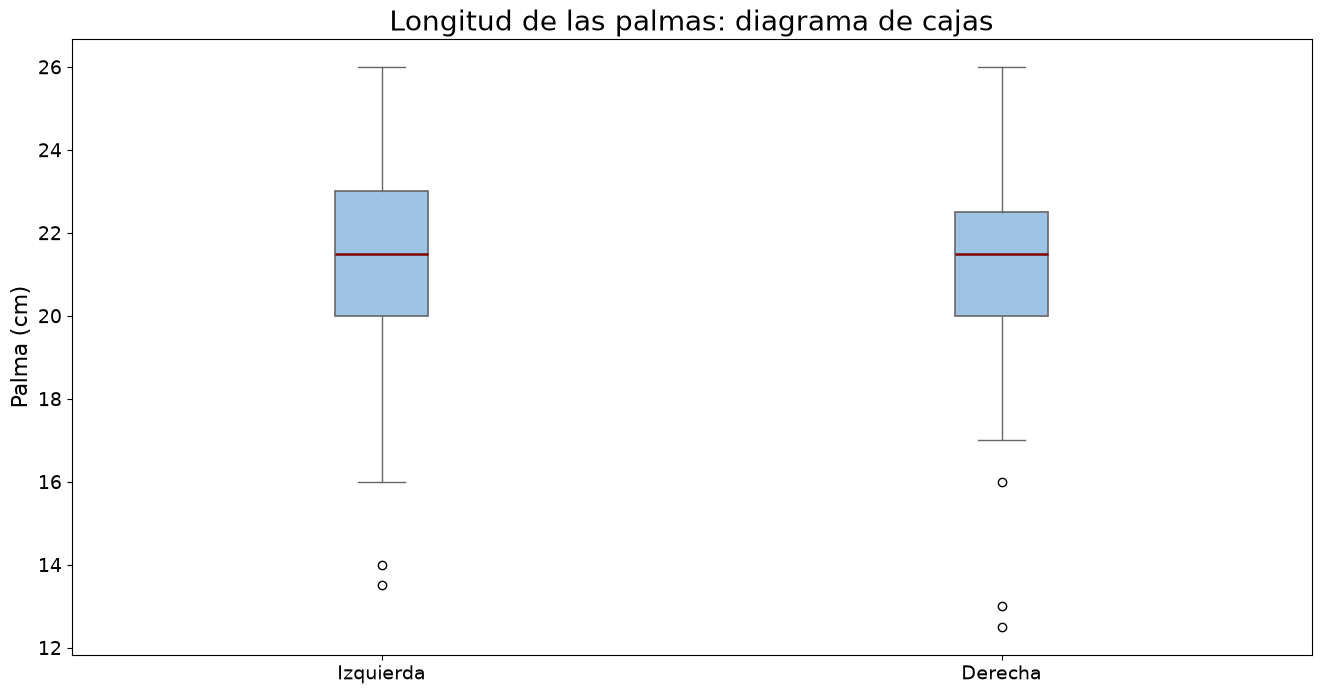

In [34]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.boxplot([pares['LftSpan'], pares['RtSpan']], tick_labels=['Izquierda', 'Derecha'],
           patch_artist=True,
           boxprops={'facecolor': '#9fc3e4', 'edgecolor': '#666666', 'linewidth': 1.2},
           whiskerprops={'color': '#666666'}, capprops={'color': '#666666'},
           medianprops={'color': '#800000', 'linewidth': 1.8})
ax.set_title('Longitud de las palmas: diagrama de cajas', fontsize=20)
ax.set_ylabel('Palma (cm)', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

#### Gráfico de dispersión de las medidas emparejadas

Cada punto representa a **una persona**: su longitud izquierda es la coordenada horizontal y la derecha la vertical. La línea granate es la bisectriz $y=x$: un punto **encima** indica palma derecha mayor; uno **debajo**, palma izquierda mayor; sobre la línea, igualdad. Así vemos a la vez la relación entre ambas medidas y las diferencias dentro de cada par. Los puntos superpuestos pueden corresponder a varias personas; el gráfico no sustituye al contraste.

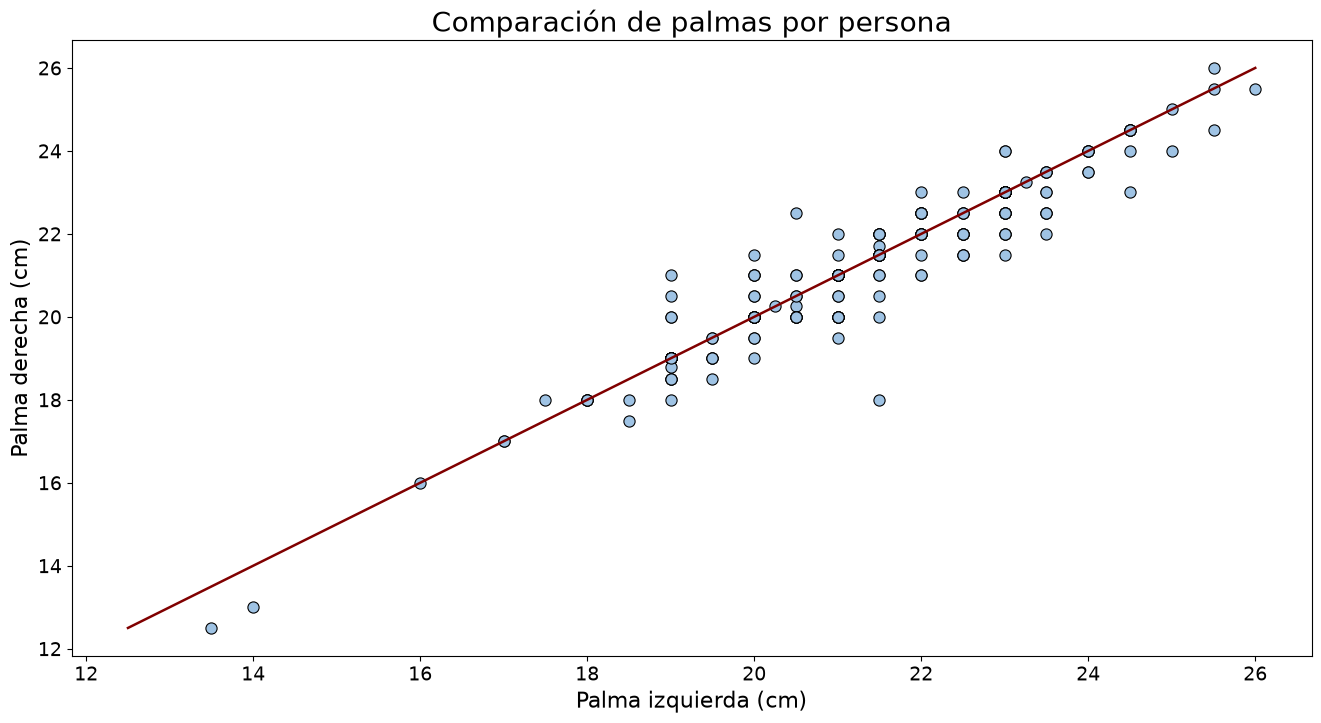

In [35]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.scatter(pares['LftSpan'], pares['RtSpan'], s=65, color='#9fc3e4',
           edgecolor='black', linewidth=0.8)
limites = [pares.min().min(), pares.max().max()]
ax.plot(limites, limites, color='#800000', linewidth=1.8)  # Referencia: derecha = izquierda.
ax.set_title('Comparación de palmas por persona', fontsize=20)
ax.set_xlabel('Palma izquierda (cm)', fontsize=16)
ax.set_ylabel('Palma derecha (cm)', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

#### Prueba t de muestras independientes: ejemplo incorrecto

Para comparar métodos, calculamos lo que daría `stats.ttest_ind` al tratar las mediciones de la mano derecha y de la izquierda como si procediesen de **personas distintas**. Plantearíamos un contraste bilateral de igualdad de medias poblacionales:

$$
\left\{
\begin{aligned}
H_0 &: \mu_{\mathrm{derecha}} = \mu_{\mathrm{izquierda}} \\
H_1 &: \mu_{\mathrm{derecha}} \ne \mu_{\mathrm{izquierda}}
\end{aligned}
\right.
$$

`equal_var=True` añade el supuesto de varianzas poblacionales iguales. **Aquí no se cumple el supuesto de independencia entre grupos:** cada longitud derecha tiene su correspondiente longitud izquierda en la misma persona. Ignorar esta relación calcula un error estándar y un valor p para un diseño distinto; aunque se muestren por motivos didácticos, **no deben usarse para concluir**. Tras los gráficos se presenta la prueba válida.

In [36]:
# SOLO PARA COMPARAR MÉTODOS: esta prueba no es válida para estas mediciones apareadas.
resultado_independiente = stats.ttest_ind(pares['RtSpan'], pares['LftSpan'], equal_var=True)
print(f'Tratamiento incorrecto como muestras independientes: t = {resultado_independiente.statistic:.4f}; '
      f'p-valor bilateral = {resultado_independiente.pvalue:.4g}')
print('No usar este valor p para sacar conclusiones: las dos medidas pertenecen a las mismas personas.')

Tratamiento incorrecto como muestras independientes: t = -0.7443; p-valor bilateral = 0.4571
No usar este valor p para sacar conclusiones: las dos medidas pertenecen a las mismas personas.


### Gráficos para datos apareados

La función siguiente prepara **cuatro vistas de los mismos pares completos**: (1) relación entre ambas palmas y recta de igualdad; (2) Bland–Altman, con la diferencia derecha − izquierda frente al promedio de cada par, la diferencia media y límites descriptivos de acuerdo (media ± 1,96 desviaciones típicas de las diferencias); (3) diferencias individuales respecto a cero; (4) perfiles que unen las dos medidas de cada persona. Estos límites de Bland–Altman **no son** un intervalo de confianza para la diferencia media.

En cada perfil hay **dos puntos**, uno para la palma izquierda y otro para la derecha de la **misma persona**, unidos por una línea. El gris tenue indica palmas iguales, el azul oscuro una derecha menor y el azul claro una derecha mayor. La línea granate gruesa une las **medias de cada lado**; no corresponde a una persona. Algunos puntos y líneas se superponen porque varias personas pueden tener las mismas medidas. Mostraremos primero **todos los pares** y después, en otra celda, solo los que difieren tras redondear.

In [37]:
def graficos_apareados(tabla, titulo='Todos los pares'):
    """Relación, Bland–Altman, diferencias individuales y perfiles por par."""
    par = tabla[['LftSpan', 'RtSpan']].dropna()
    x, y = par['LftSpan'].to_numpy(), par['RtSpan'].to_numpy()
    diff, promedio = y - x, (x + y) / 2
    fig, axes = plt.subplots(2, 2, figsize=(18, 11))

    axes[0, 0].scatter(x, y, s=65, color='#9fc3e4', edgecolor='black', linewidth=0.8)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    axes[0, 0].plot([lo, hi], [lo, hi], color='#800000', linewidth=1.8)
    axes[0, 0].set(xlabel='Izquierda (cm)', ylabel='Derecha (cm)', title='Comparación de medidas')

    axes[0, 1].scatter(promedio, diff, s=65, color='#9fc3e4', edgecolor='black', linewidth=0.8)
    media_diff = diff.mean()
    desviacion_diff = diff.std(ddof=1)
    axes[0, 1].axhline(media_diff, color='#800000', linewidth=2, label='Diferencia media')
    for nivel in (media_diff - 1.96 * desviacion_diff, media_diff + 1.96 * desviacion_diff):
        axes[0, 1].axhline(nivel, color='#800000', ls='--', linewidth=1.6)
    axes[0, 1].set(xlabel='Media de cada par (cm)', ylabel='Derecha − izquierda (cm)', title='Bland–Altman')

    axes[1, 0].scatter(np.arange(1, len(diff) + 1), diff, s=65, color='#9fc3e4',
                       edgecolor='black', linewidth=0.8)
    axes[1, 0].axhline(0, color='#800000', ls='--', linewidth=1.8)
    axes[1, 0].set(xlabel='Posición del par', ylabel='Derecha − izquierda (cm)', title='Diferencia por persona')

    ax_perfiles = axes[1, 1]
    etiquetas_vistas = set()
    for izquierda, derecha in zip(x, y):
        if derecha < izquierda:
            color, etiqueta, transparencia = '#34699a', 'Derecha menor', 0.45
        elif derecha > izquierda:
            color, etiqueta, transparencia = '#9fc3e4', 'Derecha mayor', 0.65
        else:
            color, etiqueta, transparencia = '#b0b0b0', 'Iguales', 0.25
        # Dos puntos (uno por palma) unidos por la línea de esa persona.
        ax_perfiles.plot([0, 1], [izquierda, derecha], color=color, alpha=transparencia,
                         linewidth=1.1, marker='o', markersize=4,
                         markeredgecolor='#444444', markeredgewidth=0.5,
                         label=etiqueta if etiqueta not in etiquetas_vistas else None)
        etiquetas_vistas.add(etiqueta)
    ax_perfiles.plot([0, 1], [x.mean(), y.mean()], color='#800000', linewidth=3,
                     marker='o', markersize=8, label='Media de cada lado', zorder=5)
    ax_perfiles.set(xticks=[0, 1], xticklabels=['Izquierda', 'Derecha'],
                    ylabel='Palma (cm)', title='Perfiles de cada persona')
    ax_perfiles.set_xlim(-0.1, 1.1)
    ax_perfiles.legend(loc='lower right', fontsize=10)

    for eje in axes.flat:
        eje.title.set_fontsize(18)
        eje.xaxis.label.set_fontsize(16)
        eje.yaxis.label.set_fontsize(16)
        eje.tick_params(labelsize=14)
    fig.suptitle(titulo, fontsize=20)
    fig.tight_layout()
    plt.show()

#### Fase 1: todos los pares completos

Dibujamos las cuatro vistas sin filtrar por el tamaño ni el signo de la diferencia. Las líneas horizontales grises en el gráfico de perfiles indican igualdad exacta entre ambas palmas; las inclinadas permiten identificar qué lado es mayor. En el gráfico de diferencias, el eje horizontal indica la **posición de cada par** en los datos utilizados, no el identificador original de la persona.

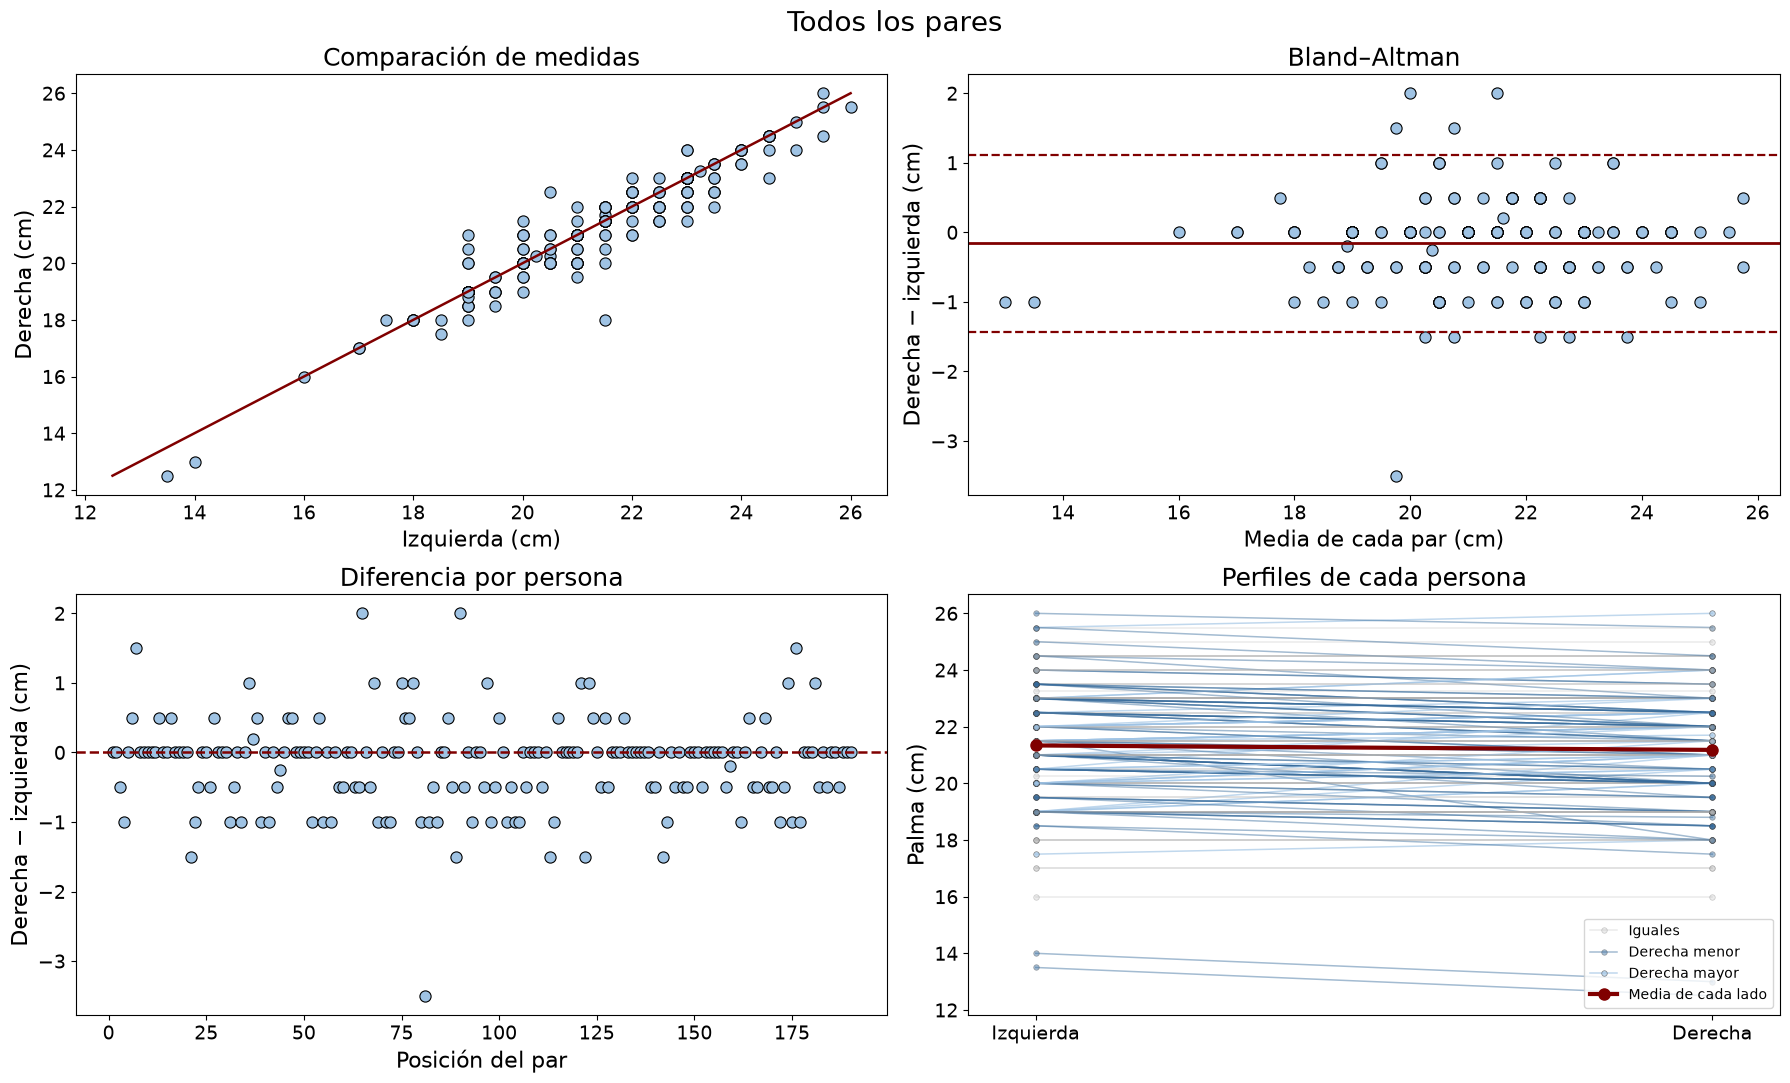

In [38]:
graficos_apareados(PennState1)

#### Fase 2: pares con longitudes redondeadas distintas

Volvemos a dibujar las cuatro vistas, pero excluimos los pares cuyas longitudes derecha e izquierda quedan **iguales al redondearlas al entero**. Antes descartamos los pares incompletos. Esto reduce la superposición de líneas horizontales y facilita ver las diferencias individuales.

**Importante:** redondear y filtrar es solo un recurso visual, no equivale a exigir una diferencia mínima fija ni justifica un nuevo contraste sobre los pares seleccionados. La prueba apareada que aparece **a continuación** utiliza todos los pares completos.

Pares seleccionados: 62 de 190


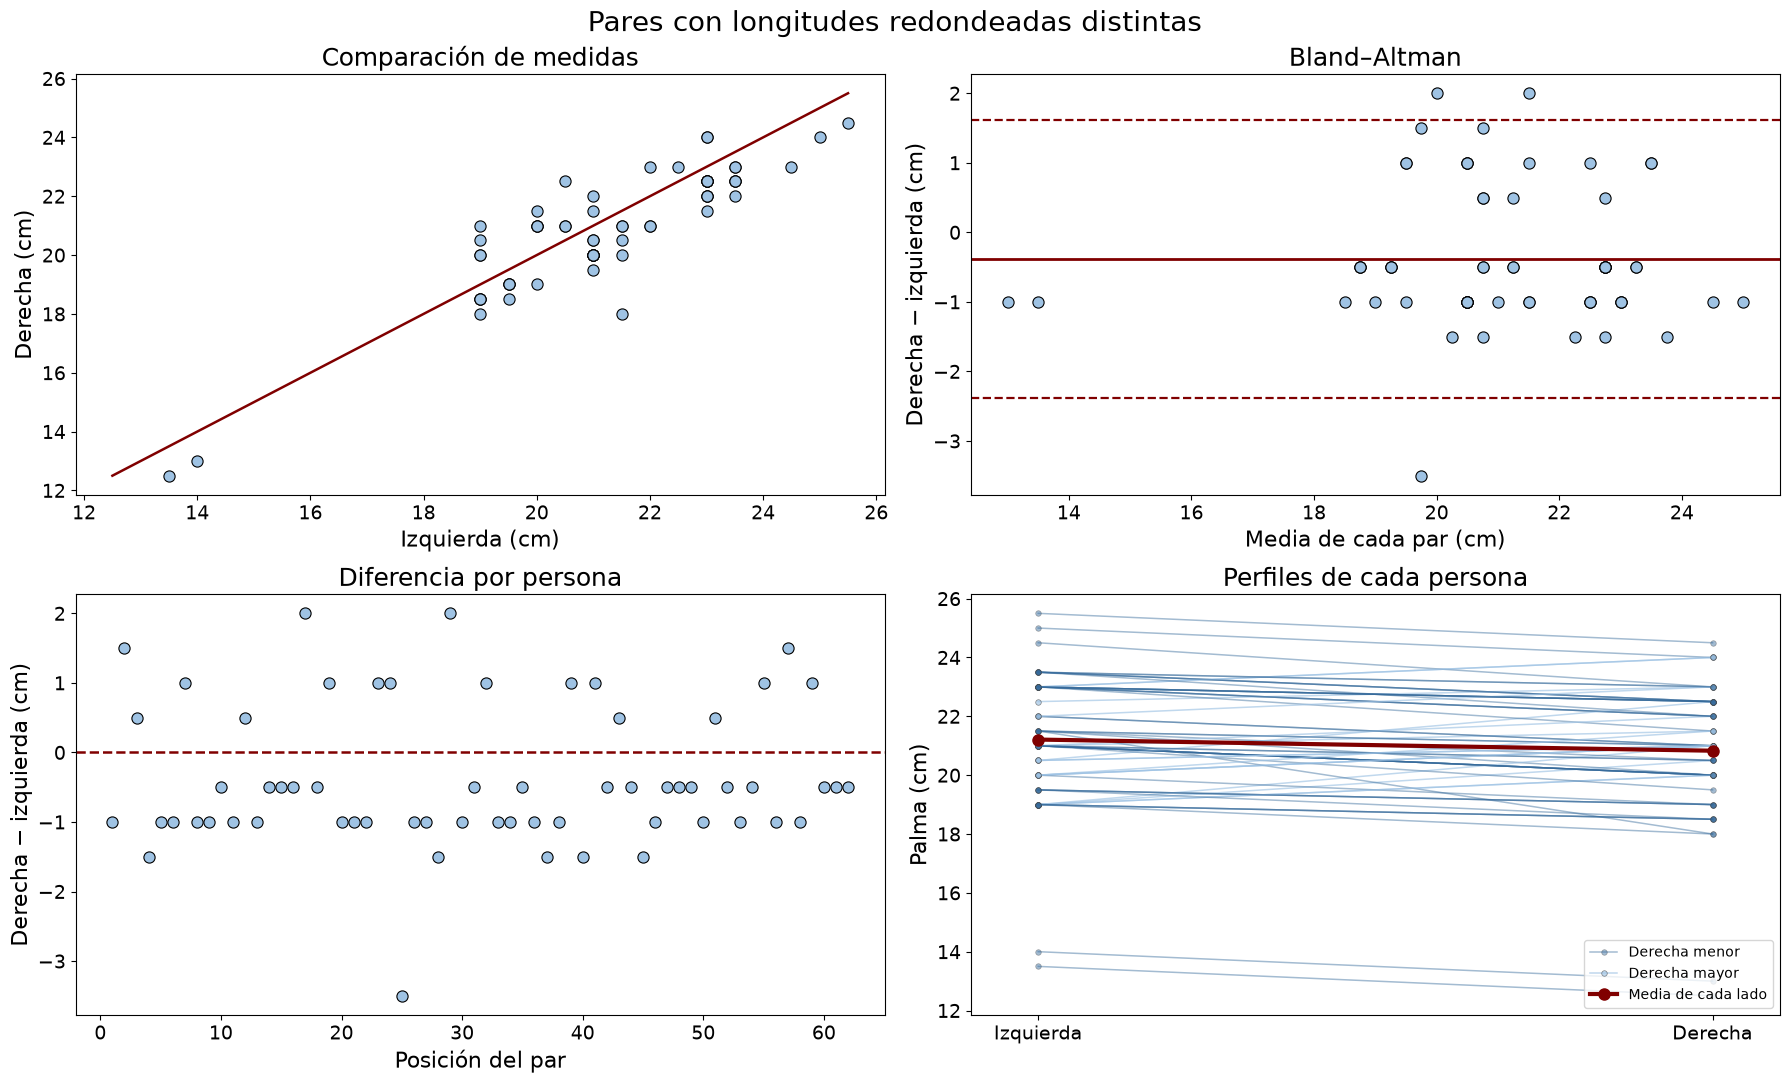

In [39]:
pares_redondeados = PennState1.dropna(subset=['LftSpan', 'RtSpan'])
distintos_redondeados = pares_redondeados['RtSpan'].round() != pares_redondeados['LftSpan'].round()
PennState1_sub = pares_redondeados.loc[distintos_redondeados]
print(f'Pares seleccionados: {len(PennState1_sub)} de {len(pares_redondeados)}')
graficos_apareados(PennState1_sub, 'Pares con longitudes redondeadas distintas')

#### Prueba t para muestras apareadas: comparación correcta

Tras examinar los gráficos, contrastamos la **diferencia media con todos los pares completos**, no solo con los 62 seleccionados para la segunda visualización. Cada persona aporta un par de valores. Definimos $D = \mathrm{RtSpan} - \mathrm{LftSpan}$ (derecha menos izquierda) y contrastamos **si la diferencia media poblacional es cero**:

$$
\left\{
\begin{aligned}
H_0 &: \mu_D = 0 \\
H_1 &: \mu_D \ne 0
\end{aligned}
\right.
$$

`stats.ttest_rel` calcula la diferencia **dentro de cada persona** y aplica una prueba t de una muestra a esas diferencias. El estadístico t mide cuántos errores estándar separan la diferencia media observada de cero; el valor p bilateral considera diferencias extremas en ambos sentidos si $H_0$ fuese cierta. Si $p<0{,}05$, rechazamos $H_0$; si no, no la rechazamos (eso no demuestra que las palmas sean idénticas). Suponemos que los pares de distintas personas son independientes y que las **diferencias** son aproximadamente normales, sobre todo si la muestra es pequeña. El signo de la diferencia media indica qué palma es mayor en promedio.

In [40]:
# Restamos las medidas de cada persona en el mismo orden que en la prueba.
diferencias_palma = pares['RtSpan'] - pares['LftSpan']
resultado_apareado = stats.ttest_rel(pares['RtSpan'], pares['LftSpan'])
print(f'Pares: {len(pares)}; diferencia media (derecha − izquierda): {diferencias_palma.mean():.2f} cm')
print(f't = {resultado_apareado.statistic:.4f}; p-valor bilateral = {resultado_apareado.pvalue:.4g}')
if resultado_apareado.pvalue < 0.05:
    print('Se rechaza H₀ al nivel del 5 %: hay evidencia de una diferencia media entre las palmas.')
else:
    print('No se rechaza H₀ al nivel del 5 %: no hay evidencia suficiente de una diferencia media.')

Pares: 190; diferencia media (derecha − izquierda): -0.16 cm
t = -3.3229; p-valor bilateral = 0.00107
Se rechaza H₀ al nivel del 5 %: hay evidencia de una diferencia media entre las palmas.


### Ejercicio 2.2

1. Crea una variable `origin2` que valga `JFK` si el origen es ese aeropuerto, y `Other` en los demás casos; puedes usar `np.where`.
2. Compara las medias del retraso en las llegadas entre `JFK` y el resto.
3. Compara los retrasos en la salida y la llegada de **los mismos vuelos**. Obtén un IC del **99,9 %** para la diferencia de medias.
4. Dibuja un gráfico de Bland–Altman para los **10 000 primeros** vuelos con retraso en la llegada inferior a 180 minutos. Utiliza las columnas de retraso en salida y llegada y la función de gráficos apareados anterior, o adapta su cálculo de medias y diferencias a esas columnas.

In [41]:
# 2.2.1 — Clasificación del aeropuerto de salida.
# Trabaja sobre datos2, que se leyó en el ejercicio 2.1.
# Revisa los valores de la columna de origen y distingue JFK del resto en una nueva columna origin2.
# Usa una condición por fila (puedes consultar np.where) y comprueba las frecuencias obtenidas.

In [42]:
# 2.2.2 — Retraso medio de JFK frente al resto: muestras independientes.
# Separa arr_delay según origin2 y excluye los retrasos ausentes de cada grupo.
# Anota los tamaños y las medias antes de comparar: ¿qué orden tendrá la diferencia?
# Piensa en los supuestos de una prueba t para grupos distintos y en cómo interpretar su valor p.

In [43]:
# 2.2.3 — Retrasos de los mismos vuelos: muestras apareadas.
# Selecciona juntos ambos retrasos y elimina las filas incompletas sin perder el emparejamiento.
# Decide qué resta vas a estudiar (llegada − salida o salida − llegada) y mantén ese orden.
# Calcula un IC bilateral para la media de las diferencias; ¿qué nivel de confianza y alfa corresponden al 99,9 %?
# La normalidad relevante para un método t es la de las diferencias, no la de cada columna por separado.

In [44]:
# 2.2.4 — Bland–Altman.
# Filtra primero por retraso de llegada < 180 y después toma las primeras 10 000 filas.
# Conserva solo los vuelos con retrasos de salida y llegada disponibles.
# Para cada vuelo, representa en horizontal el promedio de ambos retrasos y en vertical su diferencia.
# Añade la diferencia media y los límites descriptivos (media ± 1,96 desviaciones típicas).
# La función graficos_apareados espera LftSpan y RtSpan: adáptala o crea una versión para vuelos.

## Comparación de dos varianzas (opcional)

Retomamos las facturas válidas de `Plan` y `Prepaid` preparadas anteriormente. Primero exploramos gráficamente la **dispersión**; después comparamos las **varianzas poblacionales** con una prueba F y calculamos, por separado, intervalos de confianza para el cociente de varianzas y el cociente de desviaciones típicas, siempre en el orden **Plan / Prepaid**.

La prueba F y sus intervalos requieren observaciones independientes en ambos grupos y poblaciones aproximadamente **normales**. La asimetría y los valores atípicos de las facturas aconsejan interpretar los resultados con cautela.

### Exploración gráfica de la dispersión

Dibujamos las facturas de `Plan` y `Prepaid` en **dos cajas sobre la misma escala**. Una caja más alta indica mayor amplitud entre los cuartiles; también conviene comparar los bigotes y los valores atípicos. Estas diferencias visuales son descriptivas y no bastan por sí mismas para afirmar que las varianzas poblacionales difieran.

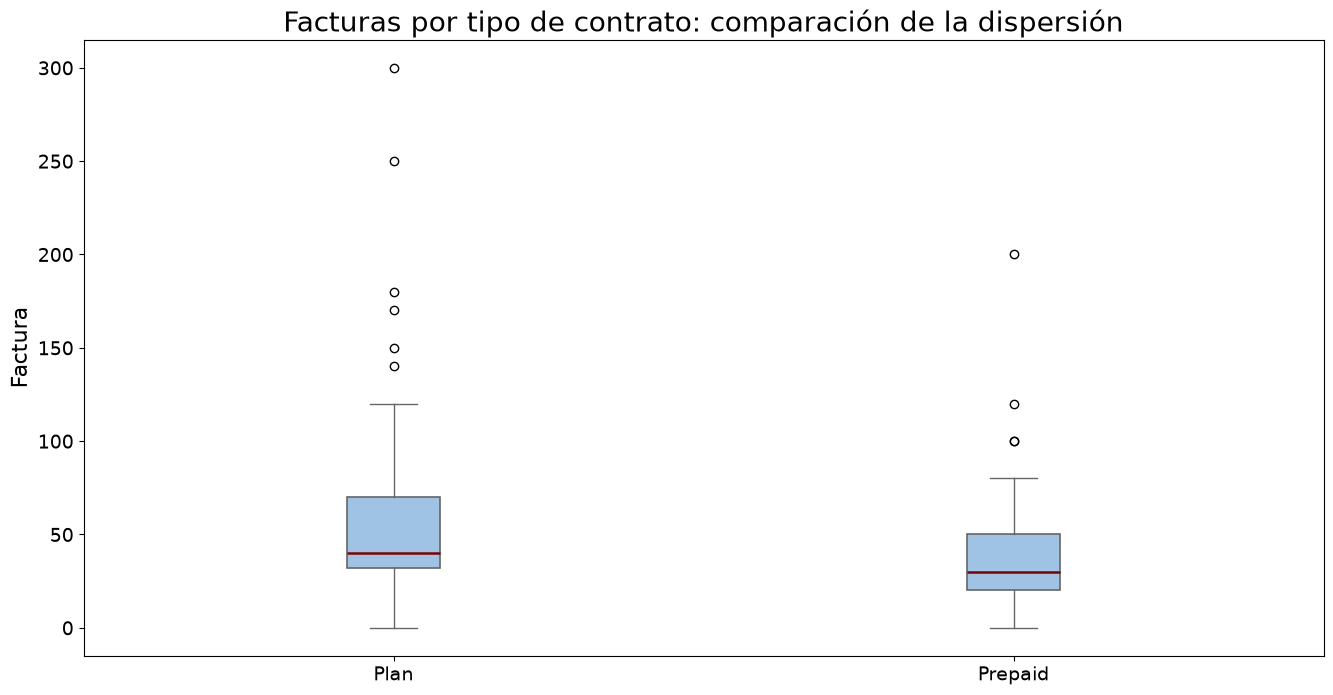

In [45]:
fig, ax = plt.subplots(figsize=(16, 8))
ax.boxplot([grupo1, grupo2], tick_labels=[nombre1, nombre2], patch_artist=True,
           boxprops={'facecolor': '#9fc3e4', 'edgecolor': '#666666', 'linewidth': 1.2},
           whiskerprops={'color': '#666666'}, capprops={'color': '#666666'},
           medianprops={'color': '#800000', 'linewidth': 1.8})
ax.set_title('Facturas por tipo de contrato: comparación de la dispersión', fontsize=20)
ax.set_ylabel('Factura', fontsize=16)
ax.tick_params(labelsize=14)
plt.show()

### Función para comparar la variabilidad

Definimos `prueba_varianzas(a, b, confianza=0.95)` para reutilizarla en otros datos, como en el ejercicio siguiente. La función elimina los ausentes de cada grupo, calcula el estadístico y el valor p de un **contraste F bilateral**, y devuelve dos intervalos de confianza: uno para $\sigma_a^2/\sigma_b^2$ y otro para $\sigma_a/\sigma_b$. El **orden de los argumentos importa**: aquí `a` es `Plan` y `b` es `Prepaid`. A continuación examinamos sus resultados paso a paso.

In [46]:
def prueba_varianzas(a, b, confianza=0.95):
    """Contraste F bilateral e IC del cociente de varianzas y desviaciones."""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    gl1, gl2 = len(a)-1, len(b)-1
    cociente = a.var(ddof=1) / b.var(ddof=1)
    pvalor = min(1, 2 * min(stats.f.cdf(cociente, gl1, gl2), stats.f.sf(cociente, gl1, gl2)))
    alfa = 1-confianza
    ic_var = (cociente/stats.f.ppf(1-alfa/2, gl1, gl2),
              cociente/stats.f.ppf(alfa/2, gl1, gl2))
    return {'F': cociente, 'p-valor': pvalor, 'IC varianzas': ic_var,
            'IC desviaciones': tuple(np.sqrt(ic_var))}

#### Contraste F bilateral: ¿son iguales las varianzas?

Comparamos las **varianzas poblacionales** de las facturas con las hipótesis:

$$
\left\{
\begin{aligned}
H_0 &: \sigma^2_{\mathrm{Plan}} = \sigma^2_{\mathrm{Prepaid}} \\
H_1 &: \sigma^2_{\mathrm{Plan}} \ne \sigma^2_{\mathrm{Prepaid}}
\end{aligned}
\right.
$$

El estadístico $F=s^2_{\mathrm{Plan}}/s^2_{\mathrm{Prepaid}}$ sería próximo a 1 si ambas dispersiones fueran parecidas. La prueba calcula un **valor p bilateral** con la distribución F y $n_{\mathrm{Plan}}-1$ y $n_{\mathrm{Prepaid}}-1$ grados de libertad. Si $p<0{,}05$, rechazamos $H_0$; en otro caso no la rechazamos, **sin demostrar** que las varianzas sean exactamente iguales. Esta prueba es sensible a desviaciones de la normalidad.

In [47]:
resultado_varianzas = prueba_varianzas(grupo1, grupo2)
print(f'Contraste F bilateral ({nombre1} / {nombre2}): '
      f'F = {resultado_varianzas["F"]:.4f}; p-valor = {resultado_varianzas["p-valor"]:.4g}')
if resultado_varianzas['p-valor'] < 0.05:
    print('Se rechaza la igualdad de varianzas al nivel del 5 %.')
else:
    print('No se rechaza la igualdad de varianzas al nivel del 5 %.')

Contraste F bilateral (Plan / Prepaid): F = 3.3331; p-valor = 3.624e-08
Se rechaza la igualdad de varianzas al nivel del 5 %.


#### IC del 95 % para el cociente de varianzas

El contraste anterior decide si hay evidencia contra la igualdad; el **intervalo de confianza** estima cuánto podría valer $\sigma^2_{\mathrm{Plan}}/\sigma^2_{\mathrm{Prepaid}}$. El cociente muestral $F$ se divide entre cuantiles de la distribución F con los grados de libertad de ambos grupos. Con `confianza=0.95`, el intervalo es del **95 %**; si se aumenta a 0,99, el intervalo suele ser más ancho. El valor **1** representa varianzas iguales: un IC que no lo incluya es coherente con rechazar la igualdad en un contraste bilateral al 5 %. Este intervalo también requiere normalidad e independencia.

In [48]:
ic_var = resultado_varianzas['IC varianzas']
print(f'IC del 95 % para σ² de {nombre1} / σ² de {nombre2}: '
      f'({ic_var[0]:.2f}, {ic_var[1]:.2f})')

IC del 95 % para σ² de Plan / σ² de Prepaid: (2.18, 5.15)


#### IC del 95 % para el cociente de desviaciones típicas

La desviación típica es la **raíz cuadrada de la varianza**. Por eso obtenemos este intervalo aplicando la raíz cuadrada a los dos límites del IC anterior: ahora estimamos $\sigma_{\mathrm{Plan}}/\sigma_{\mathrm{Prepaid}}$, no el cociente de varianzas. Un valor de **1** indica igual desviación típica; un intervalo situado completamente por encima de 1 apunta a mayor dispersión en `Plan`. El nivel de confianza y los supuestos de normalidad e independencia son los mismos que antes.

In [49]:
ic_desv = resultado_varianzas['IC desviaciones']
print(f'IC del 95 % para σ de {nombre1} / σ de {nombre2}: '
      f'({ic_desv[0]:.2f}, {ic_desv[1]:.2f})')

IC del 95 % para σ de Plan / σ de Prepaid: (1.48, 2.27)


### Ejercicio 2.3

1. Representa diagramas de cajas del retraso en la llegada según si el aeropuerto de salida es `JFK` o no.
2. Repite el diagrama de cajas **solo** para los retrasos positivos y utiliza escala vertical logarítmica (`plt.yscale('log')`).
3. Compara las varianzas y calcula un IC del **99 %** con `prueba_varianzas(..., confianza=0.99)`.

In [50]:
# 2.3.1 — Diagramas de cajas del retraso en la llegada según el origen.
# Trabaja con datos2; si aún no has creado origin2 en el ejercicio 2.2, distingue JFK del resto.
# Separa arr_delay en dos grupos y elimina los valores ausentes, pero conserva los ceros y retrasos negativos.
# Representa ambos grupos en el mismo eje y etiqueta las cajas: ¿qué muestran las medianas, la dispersión y los atípicos?

In [51]:
# 2.3.2 — Diagramas de cajas de retrasos positivos en escala logarítmica.
# Filtra primero los vuelos con arr_delay > 0 y vuelve a formar los grupos JFK y Other.
# Repite el diagrama anterior, manteniendo las etiquetas y una escala vertical común para ambos grupos.
# Cambia la escala del eje vertical a logarítmica; no calcules el logaritmo de los retrasos antes de dibujar.
# ¿Por qué hay que excluir los ceros y retrasos negativos de este gráfico? ¿Qué cambia visualmente?

In [52]:
# 2.3.3 — Comparación de varianzas e IC del 99 %.
# Vuelve a los retrasos originales de JFK y Other (no solo los positivos); elimina los valores ausentes.
# Reutiliza prueba_varianzas con confianza=0.99 y mantén claro qué grupo va primero en cada cociente.
# Examina el estadístico F, el p-valor bilateral y los IC de varianzas y desviaciones típicas.
# ¿Contienen los intervalos el valor 1? Compara tu decisión con el contraste al nivel del 1 %.
# Recuerda los supuestos de independencia y normalidad y la sensibilidad de la prueba F a los atípicos.

## Comparación de dos proporciones

Estudiamos si la **proporción de estudiantes con contrato `Prepaid`** es la misma en los dos grupos de `Gender`. Primero construimos una tabla de frecuencias, después visualizamos la distribución conjunta en un mosaico y, por último, realizamos un contraste χ². Todos los pasos utilizan únicamente estudiantes con `Gender` y `PlanType` conocidos.

### Tabla de frecuencias: género y tipo de contrato

La **tabla de contingencia** cuenta cuántos estudiantes tienen cada combinación de `Gender` (filas) y `PlanType` (columnas). `pd.crosstab` excluye las filas con valores ausentes en cualquiera de las dos variables. Para comparar la proporción de `Prepaid` entre géneros, fíjate en los casos de `Prepaid` **respecto al total de cada fila**, no solo en sus recuentos absolutos.

In [53]:
t1 = pd.crosstab(datos['Gender'], datos['PlanType'])  # Filas: género; columnas: contrato.
display(t1)

PlanType,Plan,Prepaid
Gender,,
Female,39,43
Male,37,55


### Mosaico: comparación visual de proporciones

El **mosaico** representa las mismas observaciones válidas que la tabla. La **anchura** de cada bloque de género refleja cuántas personas hay en ese grupo, mientras que la **altura relativa** de `Prepaid` dentro de cada bloque muestra su proporción en ese género. Si ambas alturas fueran similares, las proporciones observadas también lo serían. El área de cada rectángulo refleja la frecuencia conjunta; el gráfico describe los datos, pero no sustituye al contraste.

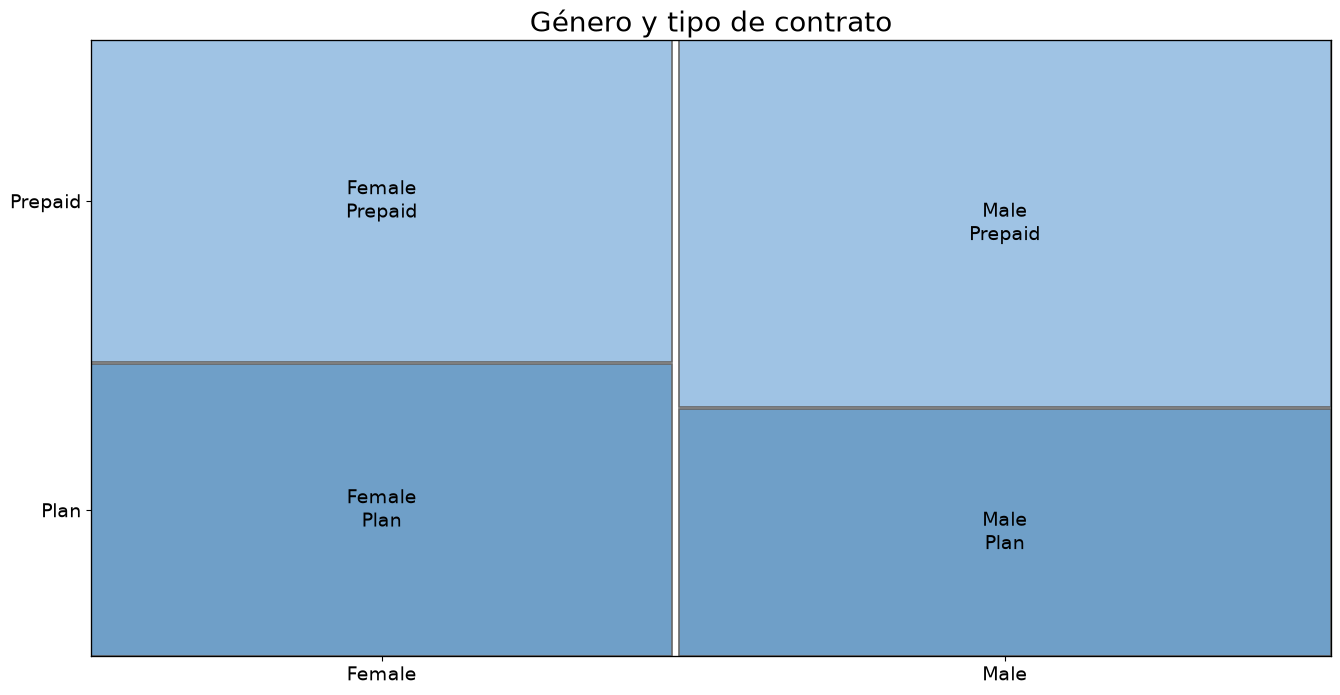

In [54]:
from statsmodels.graphics.mosaicplot import mosaic

fig, ax = plt.subplots(figsize=(16, 8))
mosaic(datos.dropna(subset=['Gender', 'PlanType']), ['Gender', 'PlanType'], ax=ax,
       properties=lambda grupo: {'facecolor': '#9fc3e4' if grupo[1] == 'Prepaid' else '#6f9fc8',
                                 'edgecolor': '#666666', 'linewidth': 1.2})
ax.set_title('Género y tipo de contrato', fontsize=20)
ax.tick_params(labelsize=14)
for etiqueta in ax.texts:
    etiqueta.set_fontsize(14)
plt.show()

### Contraste χ²: ¿es igual la proporción de prepago?

Formulamos un **contraste bilateral de independencia**, equivalente aquí a comparar las proporciones poblacionales de `Prepaid` entre los dos géneros:

$$
\left\{
\begin{aligned}
H_0 &: \pi_{\mathrm{Prepaid|Female}} = \pi_{\mathrm{Prepaid|Male}} \\
H_1 &: \pi_{\mathrm{Prepaid|Female}} \ne \pi_{\mathrm{Prepaid|Male}}
\end{aligned}
\right.
$$

La prueba χ² compara las **frecuencias observadas** de la tabla con las **esperadas si $H_0$ fuera cierta**. Para esta tabla 2 × 2 usamos la corrección de continuidad de Yates (`correction=True`). Con un nivel del 5 %, rechazamos $H_0$ si $p<0{,}05$; de lo contrario, no la rechazamos: **no demostrar una diferencia no equivale a demostrar igualdad**. El contraste supone observaciones independientes y frecuencias esperadas suficientemente grandes; `esperado` permite comprobar estas últimas.

In [55]:
chi_cuadrado, pvalor, gl, esperado = stats.chi2_contingency(t1, correction=True)
print(f'Contraste χ² de proporciones (corrección por continuidad): χ² = {chi_cuadrado:.4f}; '
      f'gl = {gl}; p-valor = {pvalor:.4g}')
print(f'Frecuencia esperada mínima: {esperado.min():.2f}')
if pvalor < 0.05:
    print('Se rechaza la igualdad de proporciones de prepago al nivel del 5 %.')
else:
    print('No se rechaza la igualdad de proporciones de prepago al nivel del 5 %.')

Contraste χ² de proporciones (corrección por continuidad): χ² = 0.6754; gl = 1; p-valor = 0.4112
Frecuencia esperada mínima: 35.82
No se rechaza la igualdad de proporciones de prepago al nivel del 5 %.


### Ejercicio 2.4

1. Crea tres variables en `datos2` (vuelos):
   - `date`: fecha completa en formato `YYYY-MM-DD`; construye la fecha con `pd.to_datetime` a partir de año, mes y día.
   - `weekend`: `True` si la fecha cae en sábado o domingo, `False` en caso contrario; puedes usar `.dt.dayofweek >= 5`.
   - `arr_delay_cat`: `True` si el vuelo llega con retraso, `False` en caso contrario. **Ten en cuenta los valores ausentes.**
2. Representa un mosaico del retraso (`arr_delay_cat`) y el fin de semana (`weekend`).
3. Comprueba si la proporción de vuelos **sin retraso** es igual en fines de semana y en el resto de los días mediante una tabla de contingencia y una prueba χ² de proporciones.

In [56]:
# 2.4.1 — Fecha, fin de semana e indicador de retraso.
# Trabaja con datos2: combina year, month y day mediante pd.to_datetime para obtener date.
# A partir del día de la semana de date, señala como weekend los sábados y domingos.
# Define arr_delay_cat: True si arr_delay > 0, False si es cero o negativo.
# Ojo: arr_delay > 0 convierte los ausentes en False; conserva esos casos como ausentes,
# por ejemplo, utilizando un booleano que admita valores ausentes.
# Comprueba algunas filas y cuenta los ausentes antes y después de crear las tres variables.

In [57]:
# 2.4.2 — Mosaico de retraso de llegada y fin de semana.
# Selecciona únicamente los vuelos con weekend y arr_delay_cat conocidos.
# Adapta el mosaico anterior cambiando Gender y PlanType por estas dos variables.
# ¿Qué anchura representa cada grupo de días y qué altura corresponde a llegadas sin retraso?
# Mantén etiquetas legibles y compara proporciones dentro de cada grupo, no solo áreas totales.

In [58]:
# 2.4.3 — Contraste χ² de la proporción de vuelos sin retraso.
# Construye una tabla de contingencia weekend × arr_delay_cat excluyendo los ausentes.
# Dentro de cada grupo de días, 'sin retraso' corresponde a arr_delay_cat == False.
# Formula H₀: la proporción de vuelos sin retraso es igual en ambos grupos; H₁: es distinta.
# Aplica chi2_contingency como en el ejemplo anterior y revisa las frecuencias esperadas.
# Contrasta el p-valor con 0,05: ¿hay evidencia de una diferencia o solo diferencias observadas?

## Errores de tipo I y tipo II (opcional)

### Simulación del error de tipo I

Estimamos la proporción de resultados significativos **cuando las medias son iguales**. Generamos dos grupos de 100 retrasos normales con media 10 y desviación 3, repetimos la prueba 1 000 veces y calculamos la fracción de valores p menores de 0,05 (error de tipo I, α). Fijamos una semilla para repetir el experimento.

In [59]:
n = 100                    # Tamaño muestral por grupo.
nsim = 1000                # Número de simulaciones.
p = []                    # Valores p de las simulaciones.
rng = np.random.default_rng(12345)
for i in range(nsim):
    RetrasosPrat = rng.normal(loc=10, scale=3, size=n)     # Retrasos: media 10 y desviación 3.
    RetrasosBarajas = rng.normal(loc=10, scale=3, size=n)  # Misma media y desviación.
    tt = stats.ttest_ind(RetrasosPrat, RetrasosBarajas, equal_var=True)
    p.append(tt.pvalue)
print('Error tipo I estimado (α):', np.mean(np.array(p) < 0.05))

Error tipo I estimado (α): 0.047


### Simulación del error de tipo II (β)

El error de tipo II es la proporción de resultados **no significativos cuando sí existe una diferencia**.

### Ejercicio 2.5

1. Por simulación, calcula β con **393 observaciones por grupo**, una diferencia de medias de **0,2** y varianza **1** en ambos grupos. Elige `n`, `nsim` y una lista de valores p; fija una semilla y, en cada simulación, genera los dos grupos normales, aplica la prueba t de muestras independientes con varianzas iguales y guarda el valor p. Calcula la proporción de valores p **mayores o iguales a 0,05**.
2. La potencia de un análisis es **1 − β**. Calcula también la potencia teórica con `statsmodels.stats.power.TTestIndPower().power(effect_size=0.2, nobs1=393, alpha=0.05, ratio=1)` y comprueba si se aproxima a la simulación.

In [60]:
# Plantilla del ejercicio 2.5: completa los puntos suspensivos y ejecuta la celda.
# from statsmodels.stats.power import TTestIndPower
# n = ...                  # Tamaño muestral.
# nsim = ...               # Número de simulaciones.
# p = []                   # Valores p de las simulaciones.
# rng = np.random.default_rng(12345)
# for i in range(nsim):
#     RetrasosPrat = rng.normal(loc=..., scale=..., size=n)
#     RetrasosBarajas = rng.normal(loc=..., scale=..., size=n)
#     tt = stats.ttest_ind(RetrasosPrat, RetrasosBarajas, equal_var=True)
#     p.append(tt.pvalue)
# beta = np.mean(np.array(p) >= 0.05)  # Probabilidad de error tipo II.
# print('Potencia simulada:', 1-beta)
# print('Potencia teórica:', TTestIndPower().power(effect_size=..., nobs1=n, alpha=0.05, ratio=1))